In [ ]:
# https://www.youtube.com/watch?v=JtiK0DOeI4A
# H(n) -> absolute distance (guess on how far this node is from the end node) G(n) -> current shortest distance from start to this point
# F(n)=G(n)+H(n)

In [7]:
!pip install astar
from astar import AStar


class MyPathFinder(AStar):

    # 1. Define the grid size
    GRID_SIZE = 6

    # 2. Define obstacles (walls)
    obstacles = {
        (1, 0),
        (1, 1),
        (1, 2),
        (3, 3)
    }

    # 3. Calculate heuristic distance (Manhattan distance)
    def heuristic_cost_estimate(self, current, goal):
        return (
            abs(current[0] - goal[0]) +
            abs(current[1] - goal[1])
        )

    # 4. Calculate the cost of moving between cells
    def distance_between(self, n1, n2):
        return 1

    # 5. Find valid neighboring cells
    def neighbors(self, node):
        x, y = node

        possible = [
            (x + 1, y),  # Right
            (x - 1, y),  # Left
            (x, y + 1),  # Up
            (x, y - 1)   # Down
        ]

        return [
            position for position in possible
            if 0 <= position[0] < self.GRID_SIZE
            and 0 <= position[1] < self.GRID_SIZE
            and position not in self.obstacles
        ]


# 6. Create the pathfinder
pathfinder = MyPathFinder()

# 7. Define starting and destination positions
start = (0, 0)
goal = (5, 5)

# 8. Run the A* algorithm
path = list(pathfinder.astar(start, goal))

# 9. Display the shortest path
if path:
    print("Shortest path:", path)
    print("Number of steps:", len(path) - 1)
else:
    print("No path found!")


# 10. Display the grid
print("\nGrid:")

for y in reversed(range(6)):
    for x in range(6):
        position = (x, y)

        if position == start:
            print(" S ", end="")
        elif position == goal:
            print(" G ", end="")
        elif position in path:
            print(" * ", end="")
        elif position in pathfinder.obstacles:
            print(" # ", end="")
        else:
            print(" . ", end="")

    print()


# Start(S), Goal(G), Obstacles(#), Path(*)

Shortest path: [(0, 0), (0, 1), (0, 2), (0, 3), (1, 3), (2, 3), (2, 4), (3, 4), (4, 4), (5, 4), (5, 5)]
Number of steps: 10

Grid:
 .  .  .  .  .  G 
 .  .  *  *  *  * 
 *  *  *  #  .  . 
 *  #  .  .  .  . 
 *  #  .  .  .  . 
 S  #  .  .  .  . 


Actual Inplementation

In [8]:
from __future__ import annotations

import argparse
import heapq
import json
import math
import struct
from dataclasses import dataclass
from pathlib import Path
from typing import Dict, List, Optional, Sequence, Tuple

MARS_RADIUS_KM = 3389.5
SOURCE_COLS = 5760
SOURCE_ROWS = 2880
SOURCE_PIXELS_PER_DEGREE = 16


@dataclass(frozen=True)
class Point:
    lon: float
    lat: float
    elev: int
    slope_percent: float = 0.0
    traversal_weight: float = 0.0


@dataclass
class Grid:
    points: List[Point]
    cols: int
    rows: int
    lon0: float
    lon1: float
    lat0: float
    lat1: float
    step: float

    def index(self, x: int, y: int) -> int:
        return y * self.cols + x

    def xy(self, index: int) -> Tuple[int, int]:
        return index % self.cols, index // self.cols


def mars_distance_km(a: Point, b: Point) -> float:
    """Great-circle distance on a spherical Mars model."""
    lat1, lat2 = math.radians(a.lat), math.radians(b.lat)
    dlat = math.radians(b.lat - a.lat)
    dlon = math.radians(b.lon - a.lon)
    hav = (
        math.sin(dlat / 2) ** 2
        + math.cos(lat1) * math.cos(lat2) * math.sin(dlon / 2) ** 2
    )
    return 2 * MARS_RADIUS_KM * math.asin(math.sqrt(min(1.0, hav)))


def load_mola_grid(
    image_path: Path,
    lon0: float = 134.0,
    lon1: float = 141.0,
    lat0: float = -9.0,
    lat1: float = -2.0,
    step: float = 0.12,
) -> Grid:
    """Read the official MOLA binary and create a consistently indexed grid."""
    if not image_path.is_file():
        raise FileNotFoundError(f"MOLA image not found: {image_path}")

    expected_bytes = SOURCE_COLS * SOURCE_ROWS * 2
    actual_bytes = image_path.stat().st_size
    if actual_bytes < expected_bytes:
        raise ValueError(f"MOLA image is incomplete: {actual_bytes} bytes")

    if step <= 0:
        raise ValueError("step must be greater than zero")
    if lon1 < lon0 or lat1 < lat0:
        raise ValueError("Grid bounds must be increasing")

    cols = math.floor((lon1 - lon0) / step) + 1
    rows = math.floor((lat1 - lat0) / step) + 1

    def sample(data: bytes, lat: float, lon: float) -> int:
        row = max(
            0,
            min(
                SOURCE_ROWS - 1,
                round((90.0 - lat) * SOURCE_PIXELS_PER_DEGREE),
            ),
        )
        col = max(
            0,
            min(SOURCE_COLS - 1, round(lon * SOURCE_PIXELS_PER_DEGREE)),
        )
        offset = (row * SOURCE_COLS + col) * 2
        return struct.unpack_from(">h", data, offset)[0]

    data = image_path.read_bytes()
    points: List[Point] = []

    for y in range(rows):
        for x in range(cols):
            lat = lat0 + y * step
            lon = lon0 + x * step
            points.append(Point(lon=lon, lat=lat, elev=sample(data, lat, lon)))

    grid = Grid(
        points=points,
        cols=cols,
        rows=rows,
        lon0=lon0,
        lon1=lon0 + (cols - 1) * step,
        lat0=lat0,
        lat1=lat0 + (rows - 1) * step,
        step=step,
    )

    if len(points) != cols * rows:
        raise AssertionError("MOLA grid indexing invariant failed")

    return grid


def build_weight_matrix(grid: Grid, slope_cap_percent: float = 35.0) -> List[float]:
    """Return one normalized traversal weight per grid cell.

    The cell grade is the maximum four-neighbor rise/run grade:

        grade_percent = abs(delta_elevation_m) / horizontal_distance_m * 100

    A weight of 0 is easy terrain and 1 is at or above slope_cap_percent.
    """
    if slope_cap_percent <= 0:
        raise ValueError("slope_cap_percent must be greater than zero")

    weights = [0.0] * len(grid.points)

    for y in range(grid.rows):
        for x in range(grid.cols):
            index = grid.index(x, y)
            point = grid.points[index]
            max_grade = 0.0

            for nx, ny in ((x - 1, y), (x + 1, y), (x, y - 1), (x, y + 1)):
                if 0 <= nx < grid.cols and 0 <= ny < grid.rows:
                    neighbor = grid.points[grid.index(nx, ny)]
                    run_m = mars_distance_km(point, neighbor) * 1000.0
                    if run_m:
                        max_grade = max(
                            max_grade,
                            abs(neighbor.elev - point.elev) / run_m * 100.0,
                        )

            weight = min(1.0, max_grade / slope_cap_percent)
            grid.points[index] = Point(
                point.lon,
                point.lat,
                point.elev,
                max_grade,
                weight,
            )
            weights[index] = weight

    return weights


def corridor_distance_km(point: Point, start: Point, goal: Point) -> float:
    """Perpendicular distance to the start-goal line in a local tangent plane."""
    mean_lat = math.radians((start.lat + goal.lat) / 2.0)

    def project(p: Point) -> Tuple[float, float]:
        return (
            math.radians(p.lon) * math.cos(mean_lat) * MARS_RADIUS_KM,
            math.radians(p.lat) * MARS_RADIUS_KM,
        )

    px, py = project(point)
    ax, ay = project(start)
    bx, by = project(goal)
    dx, dy = bx - ax, by - ay
    length_squared = dx * dx + dy * dy

    if not length_squared:
        return math.hypot(px - ax, py - ay)

    t = max(
        0.0,
        min(1.0, ((px - ax) * dx + (py - ay) * dy) / length_squared),
    )
    return math.hypot(px - (ax + t * dx), py - (ay + t * dy))


def nearest_index(grid: Grid, target_lon: float, target_lat: float) -> int:
    return min(
        range(len(grid.points)),
        key=lambda i: (
            (grid.points[i].lon - target_lon) ** 2
            + (grid.points[i].lat - target_lat) ** 2
        ),
    )


def plan_route(
    grid: Grid,
    start_lon: float = 134.5,
    start_lat: float = -5.65,
    goal_lon: float = 141.0,
    goal_lat: float = -5.08,
    terrain_weight: float = 30.0,
    distance_weight: float = 10.0,
) -> Tuple[List[Point], float]:
    """Run connected 4-neighbor A* and return (route, cumulative_cost)."""
    if terrain_weight < 0 or distance_weight < 0:
        raise ValueError("Route weights cannot be negative")

    if not any(point.traversal_weight for point in grid.points):
        build_weight_matrix(grid)

    start_index = nearest_index(grid, start_lon, start_lat)
    goal_index = nearest_index(grid, goal_lon, goal_lat)
    start = grid.points[start_index]
    goal = grid.points[goal_index]

    total_weight = terrain_weight + distance_weight or 1.0
    terrain = terrain_weight / total_weight
    distance = distance_weight / total_weight

    open_heap = [(0.0, start_index)]
    came_from: Dict[int, int] = {}
    costs = {start_index: 0.0}

    def heuristic(index: int) -> float:
        return mars_distance_km(grid.points[index], goal) * (1 + distance)

    while open_heap:
        _, current = heapq.heappop(open_heap)

        if current == goal_index:
            break

        x, y = grid.xy(current)
        here = grid.points[current]

        for nx, ny in ((x - 1, y), (x + 1, y), (x, y - 1), (x, y + 1)):
            if not (0 <= nx < grid.cols and 0 <= ny < grid.rows):
                continue

            next_index = grid.index(nx, ny)
            next_point = grid.points[next_index]

            inside_corridor = (
                min(start.lon, goal_lon) - 0.35
                <= next_point.lon
                <= max(start.lon, goal_lon) + 0.35
                and min(start.lat, goal_lat) - 0.35
                <= next_point.lat
                <= max(start.lat, goal_lat) + 0.35
            )
            if not inside_corridor:
                continue

            step_km = mars_distance_km(here, next_point)
            multiplier = 1 + terrain * next_point.traversal_weight * 8 + distance
            candidate = (
                costs[current]
                + step_km * multiplier
                + corridor_distance_km(next_point, start, goal) * 0.05
            )

            if candidate < costs.get(next_index, math.inf):
                came_from[next_index] = current
                costs[next_index] = candidate
                heapq.heappush(
                    open_heap,
                    (candidate + heuristic(next_index), next_index),
                )

    if goal_index not in costs:
        return [], math.inf

    route_indices = [goal_index]
    while route_indices[-1] != start_index:
        route_indices.append(came_from[route_indices[-1]])
    route_indices.reverse()

    return [grid.points[i] for i in route_indices], costs[goal_index]


def export_route(route: Sequence[Point], cost: float, output_path: Path) -> None:
    """Export a notebook-friendly JSON route artifact."""
    payload = {
        "source": "NASA MGS MOLA MEGDR 16 ppd, resampled 0.12 degrees",
        "elevation_reference": "MOLA areoid-relative metres",
        "mars_radius_km": MARS_RADIUS_KM,
        "cost": cost,
        "points": [point.__dict__ for point in route],
    }
    output_path.write_text(json.dumps(payload, indent=2), encoding="utf-8")


def main(argv: Optional[Sequence[str]] = None) -> None:
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument(
        "--mola",
        type=Path,
        default=Path("/content/mola-topography-16ppd.img"),
    )
    parser.add_argument(
        "--output",
        type=Path,
        default=Path("mola-route.json"),
    )
    parser.add_argument("--terrain-weight", type=float, default=30.0)
    parser.add_argument("--distance-weight", type=float, default=10.0)

    # parse_known_args ignores Jupyter's injected -f kernel.json argument.
    args, _unknown = parser.parse_known_args(argv)

    grid = load_mola_grid(args.mola)
    build_weight_matrix(grid)
    route, cost = plan_route(
        grid,
        terrain_weight=args.terrain_weight,
        distance_weight=args.distance_weight,
    )

    if not route:
        raise RuntimeError("No connected route found in the configured corridor")

    args.output.parent.mkdir(parents=True, exist_ok=True)
    export_route(route, cost, args.output)

    print(f"Grid: {grid.cols} x {grid.rows}; route points: {len(route)}")
    print(f"Route cost: {cost:.3f}; output: {args.output}")


if __name__ == "__main__":
    main()


Grid: 59 x 59; route points: 62
Route cost: 934.627; output: mola-route.json


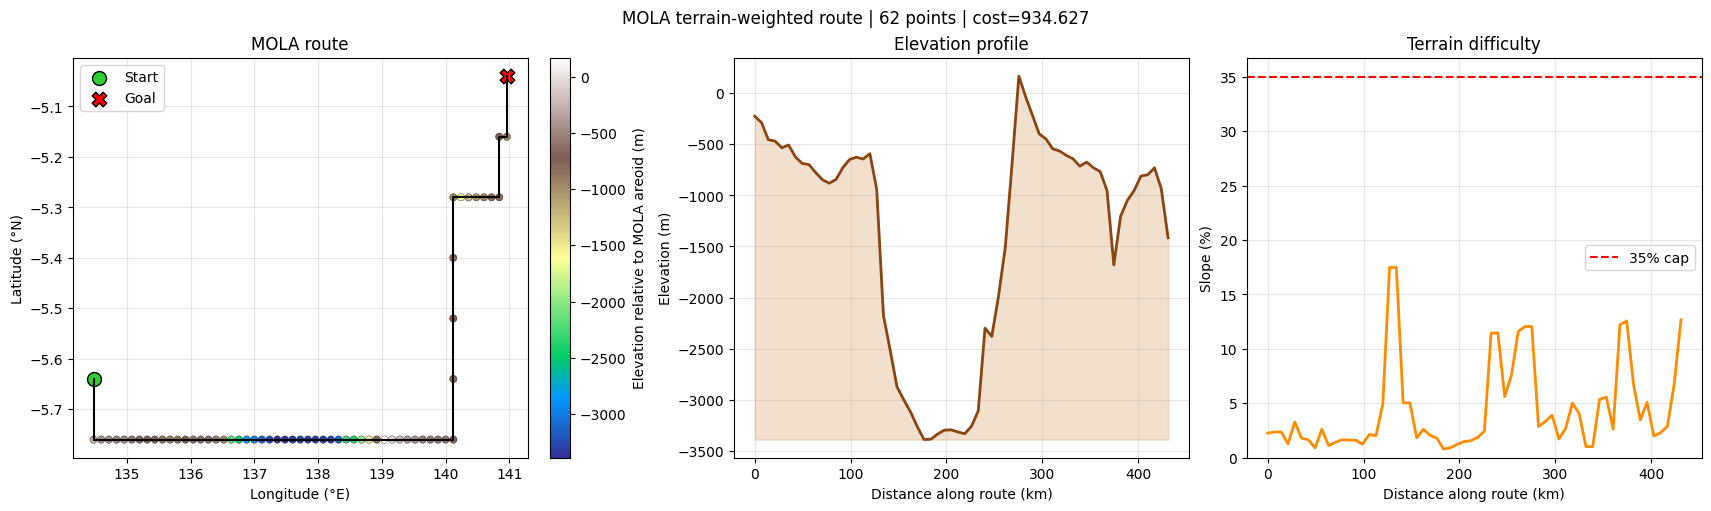

In [9]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np


def plot_route(route_file="mola-route.json"):
    route_file = Path(route_file)
    if not route_file.exists():
        raise FileNotFoundError(f"Route file not found: {route_file}")

    with route_file.open(encoding="utf-8") as f:
        payload = json.load(f)

    points = payload.get("points", [])
    if not points:
        raise ValueError(
            f"{route_file} contains no route points. Run the planner first."
        )

    lon = np.array([p["lon"] for p in points], dtype=float)
    lat = np.array([p["lat"] for p in points], dtype=float)
    elevation = np.array([p["elev"] for p in points], dtype=float)
    slope = np.array([p.get("slope_percent", 0.0) for p in points], dtype=float)

    mars_radius_km = 3389.5
    distance = np.zeros(len(points))

    for i in range(1, len(points)):
        lat1 = np.radians(lat[i - 1])
        lat2 = np.radians(lat[i])
        dlat = np.radians(lat[i] - lat[i - 1])
        dlon = np.radians(lon[i] - lon[i - 1])
        hav = (
            np.sin(dlat / 2) ** 2
            + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
        )
        distance[i] = distance[i - 1] + 2 * mars_radius_km * np.arcsin(
            np.sqrt(np.clip(hav, 0, 1))
        )

    fig, axes = plt.subplots(1, 3, figsize=(17, 5), constrained_layout=True)

    map_points = axes[0].scatter(
        lon, lat, c=elevation, cmap="terrain", s=28,
        edgecolors="black", linewidths=0.25
    )
    axes[0].plot(lon, lat, color="black", linewidth=1.5)
    axes[0].scatter(lon[0], lat[0], s=100, c="limegreen", edgecolors="black", label="Start")
    axes[0].scatter(lon[-1], lat[-1], s=110, c="red", marker="X", edgecolors="black", label="Goal")
    axes[0].set(title="MOLA route", xlabel="Longitude (°E)", ylabel="Latitude (°N)")
    axes[0].grid(alpha=0.3)
    axes[0].legend()
    fig.colorbar(map_points, ax=axes[0], label="Elevation relative to MOLA areoid (m)")

    axes[1].plot(distance, elevation, color="saddlebrown", linewidth=2)
    axes[1].fill_between(distance, elevation, elevation.min(), color="peru", alpha=0.25)
    axes[1].set(title="Elevation profile", xlabel="Distance along route (km)", ylabel="Elevation (m)")
    axes[1].grid(alpha=0.3)

    axes[2].plot(distance, slope, color="darkorange", linewidth=2)
    axes[2].axhline(35, color="red", linestyle="--", label="35% cap")
    axes[2].set(title="Terrain difficulty", xlabel="Distance along route (km)", ylabel="Slope (%)")
    axes[2].set_ylim(bottom=0)
    axes[2].grid(alpha=0.3)
    axes[2].legend()

    cost = payload.get("cost", float("nan"))
    fig.suptitle(f"MOLA terrain-weighted route | {len(points)} points | cost={cost:.3f}")
    plt.show()


plot_route("mola-route.json")
